# Descriptive analysis

In [ ]:
import re
from collections import Counter
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go
import seaborn as sns
import plotly.offline as pyo
pyo.init_notebook_mode(connected=True)
import emoji
import nltk
from nltk.corpus import stopwords as nltk_stopwords
import stopwordsiso as iso_stopwords
from unidecode import unidecode

#### Twitch dataframe

In [ ]:
twitch_df = pd.read_csv('~/Desktop/NLP_Submission/Data/4_Sentiment_data/twitch_sentiment.csv', low_memory=False)
twitch_df.head() 

In [ ]:

twitch_df = twitch_df[['author', 'message', 'timestamp', 'streamer_name', 'session_id', 'msg_clean', 'language']]
twitch_df.head()

#### Youtube dataframe

In [ ]:
youtube_df = pd.read_csv( '~/Desktop/NLP_Submission/Data/4_Sentiment_data/youtube_sentiment.csv', low_memory=False)
youtube_df.head()

In [ ]:
youtube_df = youtube_df[[ 'streamer', 'author', 'text', 'date','video_id', 'msg_clean',  'language']]
youtube_df.columns

In [ ]:
youtube_df['language'].unique()

# Info

In [ ]:
twitch_df.info()

In [ ]:
youtube_df.info()

# Functions

In [ ]:
def missing_values(df):
    missing_values = df.isna().sum()
    missing_percentage = (missing_values / len(df)) * 100
    
    missing_data = pd.DataFrame({
        'Missing Values': missing_values,
        'Percentage': missing_percentage
    })
    
    return missing_data

In [ ]:
def compute_stats(df, label="Total"):
    df = df.copy()
    df['message'] = df['message'].astype(str)

    avg_msg_length = df['message'].apply(len).mean()
    avg_capslock_chars = df['message'].apply(lambda x: sum(1 for c in x if c.isupper())).mean()
    avg_words_per_msg = df['message'].apply(lambda x: len(x.split())).mean()

    emotes = emote_pattern.findall(' '.join(df['message']))
    top_emotes = dict(Counter(emotes).most_common(10))

    return {
        'Dataset': label,
        'Avg message length': round(avg_msg_length, 2),
        'Avg capslock chars': round(avg_capslock_chars, 2),
        'Avg words per comment': round(avg_words_per_msg, 2),
        'Top emotes': top_emotes
    }


In [ ]:

def plot_streamers_distribution_by_language(df, platform):

    color_palette = [
        "#636efa", "#ef553b", "#00cc96", "#ab63fa", "#ffa15a",
        "#19d3f3", "#ff6692", "#b6e880", "#ff97ff", "#fECB52",
        "#c2c2c2", "#1f77b4", "#8c564b", "#e377c2", "#7f7f7f"
    ]


    if 'streamer' in df.columns:
        streamer_col = 'streamer'
    elif 'streamer_name' in df.columns:
        streamer_col = 'streamer_name'
    else:
        raise ValueError("DataFrame must contain either 'streamer' or 'streamer_name' column.")

    if 'language' not in df.columns:
        raise ValueError("DataFrame must contain a 'language' column.")


    counts = df.groupby('language')[streamer_col].nunique().reset_index()
    counts.columns = ['Language', 'Number of Streamers']
    counts = counts.sort_values(by='Number of Streamers', ascending=False)


    unique_languages = counts['Language'].tolist()
    color_map = {lang: color_palette[i % len(color_palette)] for i, lang in enumerate(unique_languages)}


    fig = px.bar(
        counts,
        x='Language',
        y='Number of Streamers',
        title=f'Number of Unique Streamers per Language ({platform})',
        text='Number of Streamers',
        color='Language',
        color_discrete_map=color_map
    )

    fig.update_layout(
        xaxis_title='Language',
        yaxis_title='Number of Unique Streamers',
        showlegend=False,
        plot_bgcolor='white',
        paper_bgcolor='white',
        xaxis=dict(showgrid=True, gridcolor='lightgrey'),
        yaxis=dict(showgrid=True, gridcolor='lightgrey'),
        height=700
    )

    fig.update_traces(textposition='outside')
    fig.show()

In [ ]:

def compute_and_plot_avg_word_count_distribution_plotly(
    df,
    dataset_col='language',
    streamer_col='streamer',
    message_col='message',
    min_messages_per_streamer=0,
    plot_type='box',  # or violin
    color='red', 
    platform_name=None
):

    df = df.copy()
    df[message_col] = df[message_col].astype(str)
    df['word_count'] = df[message_col].str.split().apply(len)
    
    title_base = 'Distribution of Average Message Length per Streamer by Dataset'
    if platform_name:
        title_base += f' ({platform_name})'



    if min_messages_per_streamer > 0:
        message_counts = df.groupby(streamer_col)[message_col].count()
        valid_streamers = message_counts[message_counts >= min_messages_per_streamer].index
        df = df[df[streamer_col].isin(valid_streamers)]

    avg_words_df = (
        df.groupby([dataset_col, streamer_col])['word_count']
        .mean()
        .reset_index(name='avg_words_per_message')
    )

    if plot_type == 'box':
        fig = px.box(
            avg_words_df,
            x=dataset_col,
            y='avg_words_per_message',
            points='all',
            color_discrete_sequence=[color],
            template='plotly_white',
            title=title_base
        )
    elif plot_type == 'violin':
        fig = px.violin(
            avg_words_df,
            x=dataset_col,
            y='avg_words_per_message',
            box=True,
            points='all',
            color_discrete_sequence=[color],
            template='plotly_white',
            title=title_base
        )
    else:
        raise ValueError("plot_type must be 'box' or 'violin'")

    fig.update_layout(
        xaxis_title=dataset_col.capitalize(),
        yaxis_title='Average Words per Message',
        title_x=0.5,
        height=600,
        showlegend=False
    )

    fig.show()
    return avg_words_df

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

def plot_overall_avg_word_length_distribution(
    df,
    streamer_col='streamer',
    message_col='message',
    language_col='language',
    min_messages_per_streamer=0,
    bins=30,
    platform_name=None,
    color=None
):
    df = df.copy()


    if message_col not in df.columns:
        fallback_col = 'text' if 'text' in df.columns else None
        if fallback_col:
            print(f"\nColumn '{message_col}' not found. Using '{fallback_col}' instead.")
            message_col = fallback_col
        else:
            raise ValueError("Neither 'message' nor 'text' column found in the DataFrame.")

    df[message_col] = df[message_col].astype(str)
    df['word_count'] = df[message_col].str.split().apply(len)


    platform_colors = {
        "Twitch": ("#636efa", "#f0e6f7"), 
        "YouTube": ("red", "#fce8e6")
    }

    if platform_name in platform_colors:
        color, grid_color = platform_colors[platform_name]
    else:
        color = color or "skyblue"
        grid_color = "#eeeeee"

    sns.set_style("whitegrid", {"grid.color": grid_color})

    if min_messages_per_streamer > 0:
        message_counts = df.groupby(streamer_col)[message_col].count()
        valid_streamers = message_counts[message_counts >= min_messages_per_streamer].index
        df = df[df[streamer_col].isin(valid_streamers)]


    avg_words_df = (
        df.groupby(streamer_col)['word_count']
        .mean()
        .reset_index(name='avg_words_per_message')
    )

    plt.figure(figsize=(8, 5))
    sns.histplot(avg_words_df['avg_words_per_message'], kde=True, bins=bins, color=color)
    plt.title(f'Overall Avg Words per Message per Streamer' + (f' ({platform_name})' if platform_name else ''))
    plt.xlabel('Average Words per Message')
    plt.ylabel('Number of Streamers')
    plt.tight_layout()
    plt.show()

    return avg_words_df

In [ ]:
def compare_avg_word_length_distributions_by_language( 
    df,
    language_to_highlight='English',
    streamer_col='streamer',
    message_col='message',
    language_col='language',
    min_messages_per_streamer=0,
    bins=30, 
    platform_name=None, 
    color=None
):


    df = df.copy()

    if message_col not in df.columns:
        fallback_col = 'text' if 'text' in df.columns else None
        if fallback_col:
            print(f"\nColumn '{message_col}' not found. Using '{fallback_col}' instead.")
            message_col = fallback_col
        else:
            raise ValueError("Neither 'message' nor 'text' column found in the DataFrame.")

    df[message_col] = df[message_col].astype(str)
    df['word_count'] = df[message_col].str.split().apply(len)


    platform_colors = {
        "Twitch": ("mediumorchid", "#f0e6f7"),
        "YouTube": ("lightcoral", "#fce8e6")
    }

    if platform_name in platform_colors:
        color, grid_color = platform_colors[platform_name]
    else:
        color = color or "skyblue"
        grid_color = "#eeeeee"  


    sns.set_style("whitegrid", {"grid.color": grid_color})


    if min_messages_per_streamer > 0:
        message_counts = df.groupby(streamer_col)[message_col].count()
        valid_streamers = message_counts[message_counts >= min_messages_per_streamer].index
        df = df[df[streamer_col].isin(valid_streamers)]


    avg_words_df = (
        df.groupby([language_col, streamer_col])['word_count']
        .mean()
        .reset_index(name='avg_words_per_message')
    )

    title_base = f'Avg Words per Message per Streamer – {language_to_highlight}'
    if platform_name:
        title_base += f' ({platform_name})'

    highlight_data = avg_words_df[avg_words_df[language_col] == language_to_highlight]
    plt.figure(figsize=(8, 5))
    sns.histplot(highlight_data['avg_words_per_message'], kde=True, bins=bins, color=color)
    plt.title(title_base)
    plt.xlabel('Average Words per Message')
    plt.ylabel('Number of Streamers')
    plt.tight_layout()
    plt.show()


    g = sns.displot(
        data=avg_words_df,
        x='avg_words_per_message',
        col=language_col,
        kind='hist',
        col_wrap=4,
        bins=bins,
        kde=True,
        height=3,
        aspect=1.2,
        color=color
    )
    g.set_axis_labels("Avg Words per Message", "Count")
    g.set_titles("{col_name}")
    plt.subplots_adjust(top=0.9)
    g.fig.suptitle("Avg Words per Message per Streamer by Language", fontsize=16)
    plt.show()

    return avg_words_df

In [ ]:
import plotly.express as px
import pandas as pd

def compare_streamers_distribution_by_language(df1, df2, platform1='Twitch', platform2='YouTube'):


    def process_df(df, platform_name):
        if 'streamer' in df.columns:
            streamer_col = 'streamer'
        elif 'streamer_name' in df.columns:
            streamer_col = 'streamer_name'
        else:
            raise ValueError("Each DataFrame must contain either 'streamer' or 'streamer_name'.")

        if 'language' not in df.columns:
            raise ValueError("Each DataFrame must contain a 'language' column.")

        counts = df.groupby('language')[streamer_col].nunique().reset_index()
        counts.columns = ['Language', 'Number of Streamers']
        counts['Platform'] = platform_name
        return counts

    df1_processed = process_df(df1, platform1)
    df2_processed = process_df(df2, platform2)
    combined = pd.concat([df1_processed, df2_processed], ignore_index=True)

    total_counts = combined.groupby('Language')['Number of Streamers'].sum().sort_values(ascending=False)
    sorted_languages = total_counts.index.tolist()

    platform_colors = {
        platform1: '#B197FC',  
        platform2: '#FF595E'   
    }

    fig = px.bar(
        combined,
        x='Language',
        y='Number of Streamers',
        color='Platform',
        barmode='group',
        text='Number of Streamers',
        title='Comparison of Unique Streamers per Language Between Platforms',
        color_discrete_map=platform_colors,
        category_orders={'Language': sorted_languages}  # ENFORCE order here
    )

    fig.update_layout(
        xaxis_title='Language',
        yaxis_title='Number of Unique Streamers',
        plot_bgcolor='white',
        paper_bgcolor='white',
        xaxis=dict(showgrid=True, gridcolor='lightgrey'),
        yaxis=dict(showgrid=True, gridcolor='lightgrey'),
        height=700
    )

    fig.update_traces(textposition='outside')
    fig.show()

### Emojis function

In [ ]:
import re
from collections import Counter
import pandas as pd
import plotly.express as px
from itertools import groupby, chain
from typing import Optional

emoji_pattern = re.compile(
    "[\U0001F600-\U0001F64F"
    "\U0001F300-\U0001F5FF"
    "\U0001F680-\U0001F6FF"
    "\U0001F1E0-\U0001F1FF"
    "\U00002700-\U000027BF"
    "\U0001F900-\U0001F9FF"
    "\U0001FA70-\U0001FAFF]",
    flags=re.UNICODE
)

custom_palette_30 = [
    "#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#8c564b",
    "#e377c2", "#7f7f7f", "#bcbd22", "#17becf", "#393b79", "#637939",
    "#8c6d31", "#843c39",  "#5254a3", "#6b6ecf", "#9c9ede",
    "#8ca252", "#b5cf6b", "#cedb9c", "#bd9e39", "#e7ba52", "#e7969c",
    "#d6616b", "#e7969c", "#a55194", "#ce6dbd", "#de9ed6", "#3182bd"
]


color_palette = [
    "#636efa",  
    "#ef553b",  
    "#00cc96",  
    "#ab63fa",  
    "#ffa15a",  
    "#19d3f3",
    "#ff6692",  
    "#b6e880",  
    "#ff97ff", 
    "#fECB52", 
    "#c2c2c2",  
    "#1f77b4", 
    "#8c564b",  
    "#e377c2",  
    "#7f7f7f", 
]


def extract_deduped_emojis(text):
    if pd.isna(text) or not isinstance(text, str):
        return []
    emojis = emoji_pattern.findall(text)
    return [key for key, _ in groupby(emojis)]  # deduplicate consecutive

def plot_top_emojis_by_language(
    df: pd.DataFrame,
    group_col: str = 'language',
    text_col: str = 'message',
    top_n: int = 10,
    platform_name: Optional[str] = None,
    min_total_emojis: int = 1,
    show_absolute: bool = False
):
    """
    Extracts and plots the top emojis used per group (ex.  language) as a stacked bar chart.
    Stores one deduplicated list of emojis per message for efficiency.
    """
    df = df.copy()
    df["emoji_list"] = df[text_col].apply(extract_deduped_emojis)

    all_emojis = list(chain.from_iterable(df["emoji_list"]))
    top_emojis_global = [emoji for emoji, _ in Counter(all_emojis).most_common(top_n)]

    emoji_data = []
    for group, group_df in df.groupby(group_col, observed=False):
        emojis = list(chain.from_iterable(group_df["emoji_list"]))
        if not emojis:
            continue
        filtered = [e for e in emojis if e in top_emojis_global]
        group_counter = Counter(filtered)
        total = sum(group_counter.values())
        if total < min_total_emojis:
            continue
        for emoji_char in top_emojis_global:
            count = group_counter.get(emoji_char, 0)
            emoji_data.append({
                group_col: group,
                'Emoji': emoji_char,
                'Count': count,
                'Frequency (%)': (count / total * 100) if total > 0 else 0,
                'Label': f"{(count / total * 100):.1f}%\n({count})" if total > 0 else f"0.0%\n({count})"
            })

    emoji_df = pd.DataFrame(emoji_data)
    if emoji_df.empty:
        print("No emoji data found to plot.")
        return px.bar(title="No emoji data to plot.")

    y_col = 'Count' if show_absolute else 'Frequency (%)'
    title = f"Top {top_n} Emojis by {y_col} Within Each {group_col.capitalize()}"
    if platform_name:
        title += f" ({platform_name})"

    # Create stack order: highest percentage emojis at bottom, lowest at top
    # Calculate average frequency for each emoji across all groups
    emoji_avg_freq = {}
    for emoji in top_emojis_global:
        frequencies = []
        for group in emoji_df[group_col].unique():
            group_data = emoji_df[emoji_df[group_col] == group]
            if emoji in group_data['Emoji'].values:
                freq = group_data[group_data['Emoji'] == emoji]['Frequency (%)'].iloc[0]
                frequencies.append(freq)
        emoji_avg_freq[emoji] = sum(frequencies) / len(frequencies) if frequencies else 0
    
    # Sort emojis by average frequency (highest first = bottom of stack)
    stack_order = sorted(top_emojis_global, key=lambda x: emoji_avg_freq[x], reverse=True)

    emoji_df["Emoji"] = pd.Categorical(
        emoji_df["Emoji"],
        categories=stack_order,
        ordered=True
    )

    fig = px.bar(
        emoji_df,
        x=group_col,
        y=y_col,
        color='Emoji',
        title=title,
        text='Label',
        barmode='stack',
        template='plotly_white',
        height=800,
        color_discrete_sequence=color_palette,        
        category_orders={"Emoji": stack_order}
    )

    fig.update_layout(
        xaxis_title=group_col.capitalize(),
        yaxis_title=y_col,
        title_x=0.5,
        legend_title_text='Emoji',
        margin=dict(t=80, b=100),
        legend=dict(
            orientation="h",
            yanchor="bottom",
            y=-0.3,
            xanchor="center",
            x=0.5,
            font=dict(size=12)
        )
    )

    if fig.data:
        for trace in fig.data:
            trace.textposition = "inside"
        fig.update_traces(
            textfont_size=10,
            textfont_color="white",
            textangle=0,  # Make text horizontal
            cliponaxis=False
        )

    fig.show()

## Missing values

In [ ]:
missing_values(twitch_df)

In [ ]:
missing_values(youtube_df)

In [ ]:

twitch_df.dropna(inplace=True)
youtube_df.dropna(inplace=True)

# Descriptive analysis

## Unique Streamer per Language in each Plartform

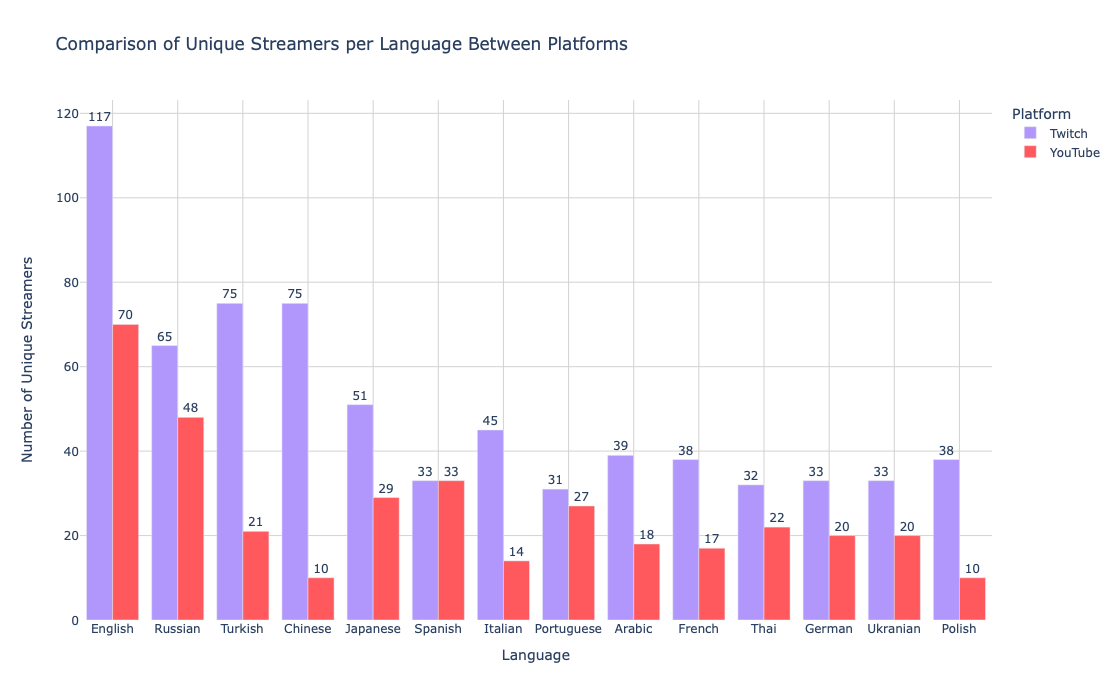

In [ ]:
compare_streamers_distribution_by_language(twitch_df, youtube_df, platform1='Twitch', platform2='YouTube')

## Twitch

In [ ]:
plot_streamers_distribution_by_language(twitch_df, platform='Twitch')

In [ ]:
# Twitch global emotes list
twitch_emotes = [
    "Kappa", "PogChamp", "LUL", "4Head", "Kreygasm", "BibleThump", "FailFish", "ResidentSleeper", "WutFace", "HeyGuys",
    "KappaPride", "DansGame", "VoHiYo", "NotLikeThis", "CoolStoryBob", "BabyRage", "KappaRoss", "MrDestructoid",
    "PepeLaugh", "FeelsBadMan", "FeelsGoodMan", "OMEGALUL", "monkaS", "Pog", "EZ", "Sadge", "KEKW"
]

# Compile regex pattern for efficiency
emote_pattern = re.compile(r'\b(?:' + '|'.join(re.escape(emote) for emote in twitch_emotes) + r')\b')


twitch_results = []

# Global stats
twitch_results.append(compute_stats(twitch_df))

# Stats per language
for lang, lang_df in twitch_df.groupby('language'):
    twitch_results.append(compute_stats(lang_df, label=lang))

# Convert to DataFrame and display
results_df = pd.DataFrame(twitch_results)

In [ ]:
twitch_results

### Average Message lenght, Capslock, Words per comment

In [ ]:
# Twitch

import plotly.graph_objects as go

# === 1. BASIC METRICS ===
basic_metrics = ['Avg message length', 'Avg capslock chars', 'Avg words per comment']
datasets = results_df['Dataset'].tolist()

#datasets = datasets.sort_values(by='Avg message length')

fig1 = go.Figure()

# Add a trace for each metric
for metric in basic_metrics:
    fig1.add_trace(go.Bar(
        name=metric,
        x=datasets,
        y=results_df[metric],
        text=results_df[metric].round(2),
        textposition='auto'
    ))

# Update layout
fig1.update_layout(
    title="Average Chat Metrics per Dataset (Language) - Twitch",
    xaxis_title="Dataset / Language",
    yaxis_title="Value",
    barmode='group',
    template='plotly_white'
)

fig1.show()

### Emotes

In [ ]:
import plotly.express as px

# === Extract top emotes per dataset/language ===
top_emote_rows = []

for _, row in results_df.iterrows():
    dataset = row["Dataset"]
    top_emotes = row["Top emotes"]
    total = sum(top_emotes.values())
    for emote, count in top_emotes.items():
        percent = count / total * 100 if total > 0 else 0
        top_emote_rows.append({
            "Dataset": dataset,
            "Emote": emote,
            "Frequency (%)": round(percent, 2)
        })

# Create DataFrame
top_emote_df = pd.DataFrame(top_emote_rows)

# Sort datasets for consistent plotting order
datasets_ordered = results_df['Dataset'].tolist()

# Plot
fig = px.bar(
    top_emote_df,
    x="Dataset",
    y="Frequency (%)",
    color="Emote",
    title="Top 10 Emotes – Percentage Share Within Each Dataset/Language (Twitch)",
    text="Frequency (%)",
    barmode="stack",
    template="plotly_white",
    height=900
)

fig.update_traces(textposition="inside")
fig.update_layout(
    xaxis={'categoryorder': 'array', 'categoryarray': datasets_ordered}
)

fig.show()


### Emojis

In [ ]:
plot_top_emojis_by_language(
    df=twitch_df,
    group_col='language',
    text_col='message',
    top_n=15,
    platform_name='Twitch'
)

### Average Words 

In [ ]:
# Average Word count per Streamer per  Language
twitch_df.rename(columns={'streamer_name': 'streamer'}, inplace=True)

avg_words_df = compute_and_plot_avg_word_count_distribution_plotly(
    df=twitch_df,
    dataset_col='language',
    streamer_col='streamer',
    message_col='message',
    min_messages_per_streamer=0,
    plot_type='box',
    color='purple', 
    platform_name='Twitch'
)

In [ ]:
avg_words_df = plot_overall_avg_word_length_distribution(
    df=twitch_df,
    platform_name='Twitch', 
    streamer_col='streamer_name'
)

In [ ]:
# Compare distribution of avg word per streamer per language
avg_words_df = compare_avg_word_length_distributions_by_language(
    df=twitch_df,
    language_to_highlight='English',
    min_messages_per_streamer=0,
    bins=50,
    platform_name='Twitch',
    color='purple'
)




## Youtube

In [ ]:
plot_streamers_distribution_by_language(youtube_df, platform='Youtube')

In [ ]:
# Calling function compute_stats and aggregating per language
youtube_results = []

youtube_df.rename(columns={'text': 'message'}, inplace=True)

# Global stats
youtube_results.append(compute_stats(youtube_df))

# Stats per language
for lang, lang_df in twitch_df.groupby('language'):
    youtube_results.append(compute_stats(lang_df, label=lang))

# Convert to DataFrame and display
results_youtube = pd.DataFrame(youtube_results)

youtube_results[0:100]

### Average Message lenght, Capslock, Words per comment

In [ ]:
import plotly.graph_objects as go

#  BASIC METRICS 
basic_metrics = ['Avg message length', 'Avg capslock chars', 'Avg words per comment']
datasets = results_youtube['Dataset'].tolist()

#datasets = datasets.sort_values(by='Avg message length')

fig1 = go.Figure()

# Add a trace for each metric
for metric in basic_metrics:
    fig1.add_trace(go.Bar(
        name=metric,
        x=datasets,
        y=results_youtube[metric],
        text=results_youtube[metric].round(2),
        textposition='auto'
    ))

# Update layout
fig1.update_layout(
    title="Average Chat Metrics per Dataset (Language) - Youtube",
    xaxis_title="Dataset / Language",
    yaxis_title="Value",
    barmode='group',
    template='plotly_white'
)

fig1.show()

### Emotes

In [ ]:
import plotly.express as px

# === Extract top emotes per dataset/language ===
top_emote_rows2 = []

for _, row in results_youtube.iterrows():
    dataset = row["Dataset"]
    top_emotes = row["Top emotes"]
    total = sum(top_emotes.values())
    for emote, count in top_emotes.items():
        percent = count / total * 100 if total > 0 else 0
        top_emote_rows2.append({
            "Dataset": dataset,
            "Emote": emote,
            "Frequency (%)": round(percent, 2)
        })

# Create DataFrame
top_emote_df = pd.DataFrame(top_emote_rows2)

# Sort datasets for consistent plotting order
datasets_ordered = results_youtube['Dataset'].tolist()

# Plot
fig = px.bar(
    top_emote_df,
    x="Dataset",
    y="Frequency (%)",
    color="Emote",
    title="Top 10 Emotes – Percentage Share Within Each Dataset/Language (Youtube)",
    text="Frequency (%)",
    barmode="stack",
    template="plotly_white",
    height=900
)

fig.update_traces(textposition="inside")
fig.update_layout(
    xaxis={'categoryorder': 'array', 'categoryarray': datasets_ordered}
)

fig.show()


### Emojis

In [ ]:
plot_top_emojis_by_language(
    df=youtube_df,
    group_col='language',
    text_col='message',
    top_n=15,
    platform_name='YouTube'
)

### Average Words

In [ ]:
#Distribution of messages per streamer

avg_words_df = compute_and_plot_avg_word_count_distribution_plotly(
    df=youtube_df,
    dataset_col='language',
    streamer_col='streamer',
    message_col='message',
    min_messages_per_streamer=0,
    plot_type='box',
    color='red', 
    platform_name='Youtube'
)


In [ ]:
avg_words_df = plot_overall_avg_word_length_distribution(
    df=youtube_df,
    platform_name='YouTube', 
    streamer_col='streamer'
)

In [ ]:
# Compare distribution of avg word per streamer per language
avg_words_df = compare_avg_word_length_distributions_by_language(
    df=youtube_df,
    language_to_highlight='English',
    min_messages_per_streamer=30,
    bins=50,
    platform_name='Youtube',
    color='red'
)


## Average Chat Metrics per Language — Twitch vs YouTube

### Average words per Streamer - Box Plot

In [ ]:
# Rename streamer column for consistency
twitch_df.rename(columns={'streamer_name': 'streamer'}, inplace=True)
youtube_df.rename(columns={'streamer': 'streamer'}, inplace=True)
twitch_df.rename(columns={'text': 'text'}, inplace=True)
youtube_df.rename(columns={'message': 'text'}, inplace=True)

# Helper function to compute word counts per streamer/language
def compute_avg_word_count(df, platform_name, msg_col="message"):
    df = df.copy()
    df["word_count"] = df[msg_col].apply(lambda x: len(str(x).split()))
    return (
        df.groupby(["streamer", "language"])["word_count"]
        .mean()
        .reset_index(name="avg_word_count")
        .assign(platform=platform_name)
    )

# Apply to Twitch and YouTube
twitch_avg = compute_avg_word_count(twitch_df, "Twitch", msg_col="message")
youtube_avg = compute_avg_word_count(youtube_df, "YouTube", msg_col="text")

# Combine
combined_avg_df = pd.concat([twitch_avg, youtube_avg], ignore_index=True)

# Sort by YouTube average word count
youtube_sorted = (
    combined_avg_df[combined_avg_df["platform"] == "YouTube"]
    .groupby("language")["avg_word_count"]
    .mean()
    .sort_values(ascending=False)
    .index.tolist()
)

In [ ]:

combined_avg_df[combined_avg_df["platform"] == "YouTube"]["language"].value_counts()

In [ ]:
import plotly.express as px

fig = px.box(
    combined_avg_df,
    x="language",
    y="avg_word_count",
    color="platform",
    color_discrete_map={"Twitch": "purple", "YouTube": "red"},
    points="all",
    title="Average Words per Comment per Streamer by Language — Twitch vs YouTube",
    labels={"language": "Language", "avg_word_count": "Avg Words per Comment"},
    category_orders={"language": youtube_sorted}  # <-- sort x-axis here
)

fig.update_layout(
    height=600,
    width=1200,
    boxmode='group',
    font=dict(size=13),
    title_x=0.5,
    plot_bgcolor='white',
    paper_bgcolor='white',
    legend=dict(
        orientation="h",
        y=1.05,
        x=0.5,
        xanchor="center"
    )
)

fig.update_xaxes(
    tickangle=45,
    gridcolor="lightgray"
)
fig.update_yaxes(
    gridcolor="lightgray"
)

fig.show()

In [ ]:
# Only run this if you haven't computed the other metrics yet
twitch_df["platform"] = "Twitch"
youtube_df["platform"] = "YouTube"

twitch_df = twitch_df.rename(columns={"streamer_name": "streamer"})

def compute_streamer_metrics(df, platform, msg_col):
    df = df.copy()
    df["word_count"] = df[msg_col].apply(lambda x: len(str(x).split()))
    df["char_count"] = df[msg_col].apply(lambda x: len(str(x)))
    df["caps_count"] = df[msg_col].apply(lambda x: sum(1 for c in str(x) if c.isupper()))
    
    return (
        df.groupby(["streamer", "language"]).agg({
            "word_count": "mean",
            "char_count": "mean",
            "caps_count": "mean"
        }).reset_index().assign(platform=platform)
    )

twitch_metrics = compute_streamer_metrics(twitch_df, "Twitch", "message")
youtube_metrics = compute_streamer_metrics(youtube_df, "YouTube", "text")

combined_avg_df = pd.concat([twitch_metrics, youtube_metrics], ignore_index=True)
import plotly.express as px

metric_columns = {
    #"word_count": "Avg Words per Comment",
    "char_count": "Average Message Length (in characters)",
    "caps_count": "Average CAPS Characters (in characters)"
}

# Sort by YouTube word count (or char count) for consistent language order
youtube_sorted = (
    combined_avg_df[combined_avg_df["platform"] == "YouTube"]
    .groupby("language")["word_count"]
    .mean()
    .sort_values(ascending=False)
    .index.tolist()
)

# Loop over each metric and plot
for metric_col, display_name in metric_columns.items():
    fig = px.box(
        combined_avg_df,
        x="language",
        y=metric_col,
        color="platform",
        color_discrete_map={"Twitch": "purple", "YouTube": "red"},
        points="all",
        title=f"{display_name} per Streamer by Language — Twitch vs YouTube",
        labels={"language": "Language", metric_col: display_name},
        category_orders={"language": youtube_sorted}
    )

    fig.update_layout(
        height=600,
        width=1000,
        boxmode='group',
        font=dict(size=13),
        title_x=0.5,
        plot_bgcolor='white',
        paper_bgcolor='white',
        legend=dict(
            orientation="h",
            y=1.05,
            x=0.5,
            xanchor="center"
        )
    )

    fig.update_xaxes(
        tickangle=45,
        gridcolor="lightgray"
    )
    fig.update_yaxes(
        gridcolor="lightgray"
    )

    fig.show()

In [ ]:
import plotly.io as pio

# Save as a standalone HTML file with all JS embedded
pio.write_html(fig, file="my_plot.html", auto_open=False, include_plotlyjs="cdn")